# Notebook 2 — XAI para SVM: ¿qué impulsa la demanda?

**Técnicas de ML Supervisado · SVM** · Michael Lata

El SVR de demanda (Notebook 1) es preciso, pero internamente es una **caja negra**:
$f(\mathbf{x})=\sum_{i\in SV}\alpha_i K(\mathbf{x}_i,\mathbf{x})+b$. Para que una
empresa **confíe y actúe** sobre sus predicciones hay que explicarlo. Aplicamos XAI:

1. **Importancia por permutación** — qué *features* mueven más la predicción.
2. **Dependencia parcial (PDP)** — la forma con que cada factor afecta la demanda.
3. **SHAP** — atribución global y **local** (explicar una predicción concreta).

Esta explicabilidad es, junto con su simplicidad, lo que hace a la SVM **más atractiva
para un negocio** que una red neuronal opaca.

## 1. Cargar el modelo y los datos del Notebook 1

In [1]:
import numpy as np, matplotlib.pyplot as plt, joblib
from pathlib import Path
RNG = 42; np.random.seed(RNG); plt.rcParams["figure.dpi"] = 110
ART = Path("artefactos")

svr  = joblib.load(ART/"svr_demanda.joblib")
meta = joblib.load(ART/"meta_demanda.joblib")
d = np.load(ART/"datos_demanda.npz")
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
FEATURES = meta["features"]
print("SVR:", meta["best_params"])
print("Métricas SVR:", {k: round(v,3) for k,v in meta["metrics_svr"].items()})
print("Features:", FEATURES)

SVR: {'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamma': 0.05, 'svr__kernel': 'rbf'}
Métricas SVR: {'rmse': 5.11, 'mae': 3.646, 'r2': 0.424}
Features: ['cantidad_vendida', 'dia_semana', 'mes', 'es_weekend', 'es_feriado', 'dias_desde_inicio', 'proporcion_stock', 'categoria_encoded', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_std_7']


## 2. Importancia por permutación (global)

Cuánto **empeora el RMSE** al barajar cada variable. Cuanto más sube el error, más
depende el modelo de esa variable.

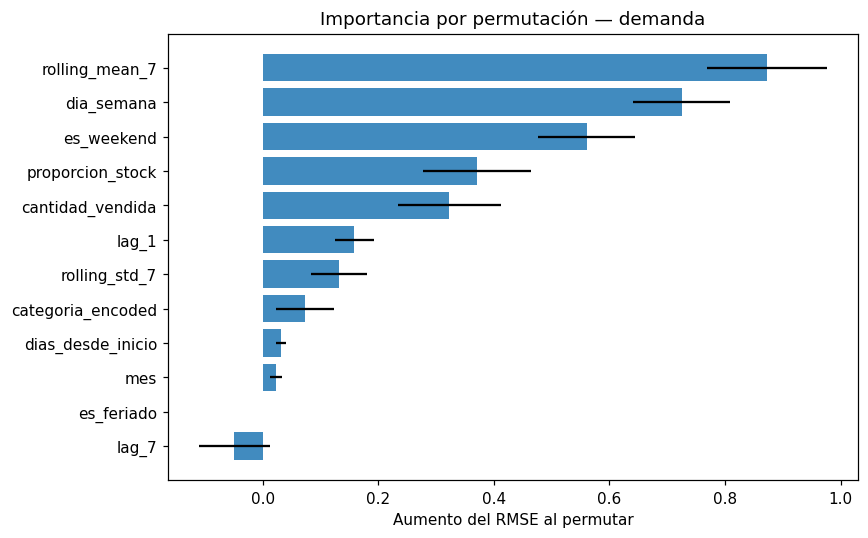

Top 5 factores de la demanda:
  rolling_mean_7     +0.873
  dia_semana         +0.725
  es_weekend         +0.561
  proporcion_stock   +0.371
  cantidad_vendida   +0.323


In [2]:
from sklearn.inspection import permutation_importance
r = permutation_importance(svr, X_test, y_test, n_repeats=20, random_state=RNG,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
order = np.argsort(r.importances_mean)
plt.figure(figsize=(8,5))
plt.barh(np.array(FEATURES)[order], r.importances_mean[order],
         xerr=r.importances_std[order], color="C0", alpha=0.85)
plt.xlabel("Aumento del RMSE al permutar"); plt.title("Importancia por permutación — demanda")
plt.tight_layout(); plt.show()
print("Top 5 factores de la demanda:")
for i in order[::-1][:5]: print(f"  {FEATURES[i]:18s} {r.importances_mean[i]:+.3f}")

## 3. Dependencia parcial (PDP) de los factores clave

Muestra **cómo cambia la demanda predicha** según el valor de cada factor (efecto
promedio). Revela patrones accionables para el negocio.

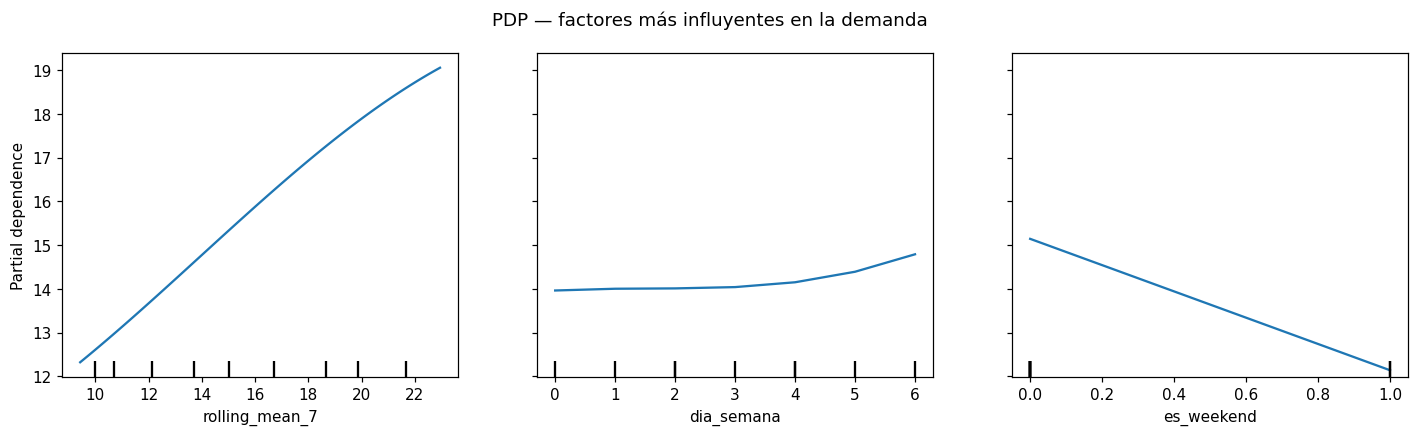

In [3]:
from sklearn.inspection import PartialDependenceDisplay
top3 = [int(i) for i in order[::-1][:3]]
fig, ax = plt.subplots(figsize=(13,4))
PartialDependenceDisplay.from_estimator(svr, X_test, top3, feature_names=FEATURES, ax=ax)
fig.suptitle("PDP — factores más influyentes en la demanda"); plt.tight_layout(); plt.show()

## 4. SHAP: atribución por valores de Shapley

Reparte cada predicción de demanda entre las *features*. Como el SVR-RBF no es lineal,
usamos un explicador *model-agnostic* sobre `predict`, con un *background* reducido
para que corra rápido.

In [4]:
import shap
print("SHAP", shap.__version__)
rng = np.random.default_rng(RNG)
bg  = X_train[rng.choice(len(X_train), 50, replace=False)]
Xe  = X_test[rng.choice(len(X_test), 150, replace=False)]
masker = shap.maskers.Independent(bg, max_samples=50)
explainer = shap.Explainer(svr.predict, masker, algorithm="permutation", feature_names=FEATURES)
sv = explainer(Xe, max_evals=400, silent=True)
print("SHAP listo:", sv.values.shape)

/home/ing_michi/venvs/cv-ai311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP 0.51.0


SHAP listo: (150, 12)


### 4.1. Importancia global SHAP

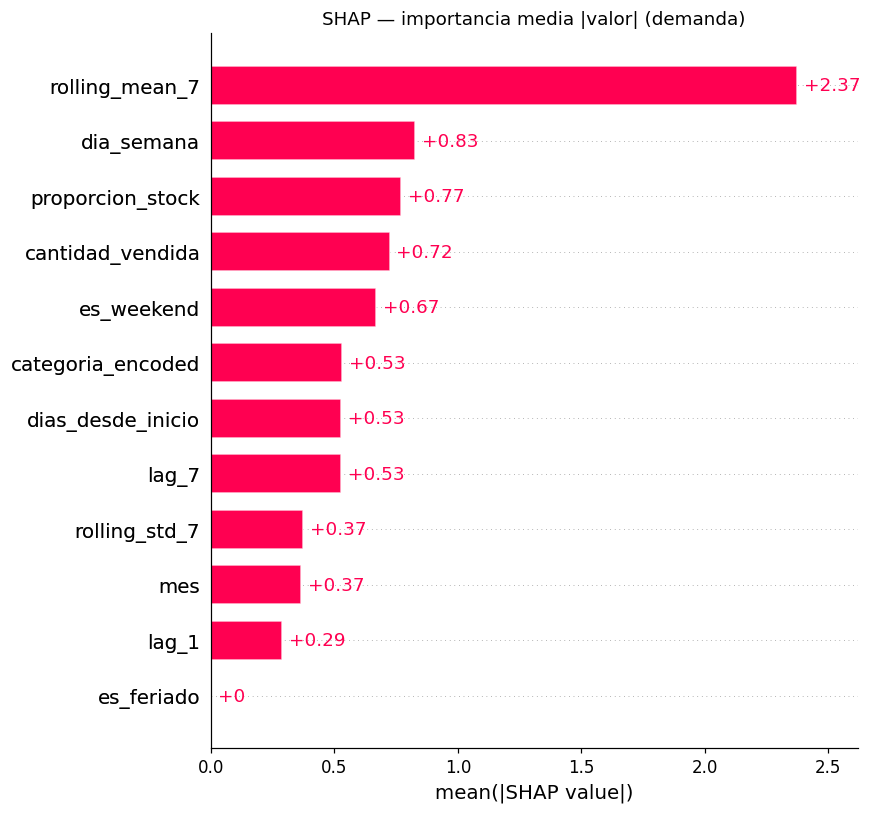

In [5]:
shap.plots.bar(sv, max_display=12, show=False)
plt.title("SHAP — importancia media |valor| (demanda)"); plt.tight_layout(); plt.show()

### 4.2. *Beeswarm*: dirección del efecto
Cada punto es un día-producto. Derecha → empuja la demanda al alza; izquierda → a la
baja. Color = valor del factor (rojo alto, azul bajo).

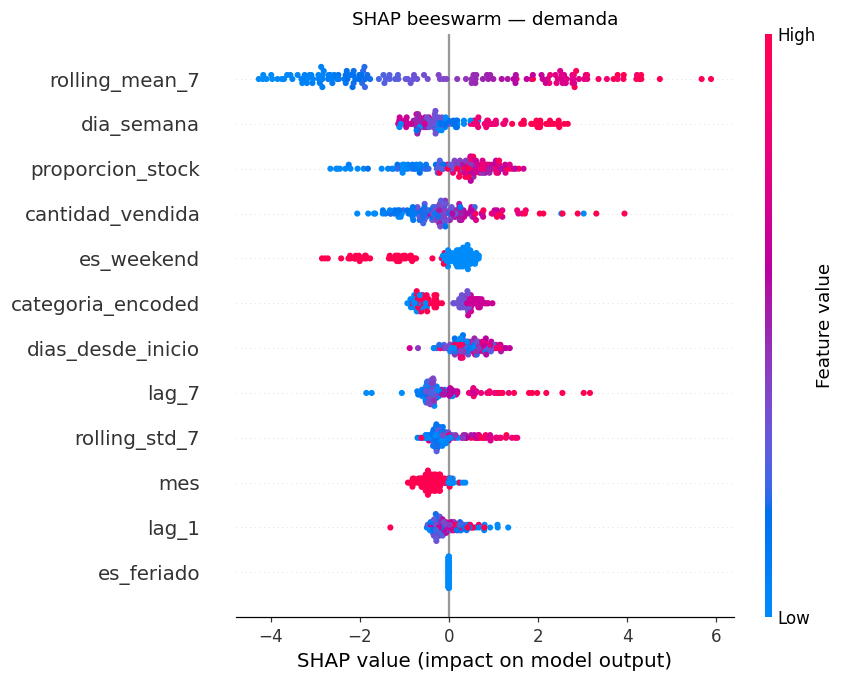

In [6]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP beeswarm — demanda"); plt.tight_layout(); plt.show()

### 4.3. Explicación **local**: dos predicciones concretas
Para un negocio lo más útil es entender una predicción individual: qué factores
empujaron la demanda estimada de un día concreto (*waterfall*).


=== día de MAYOR demanda predicha: 28.0 unidades ===


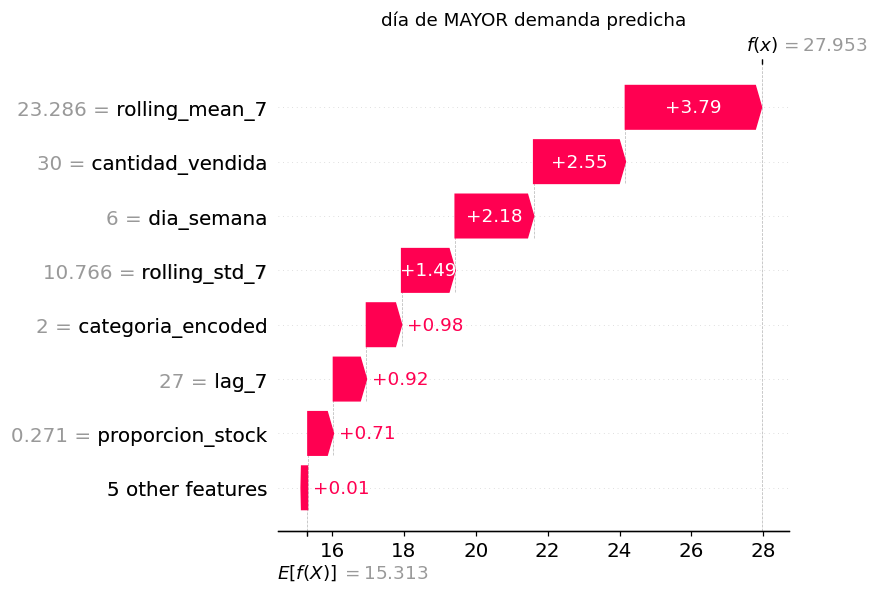


=== día de MENOR demanda predicha: 7.1 unidades ===


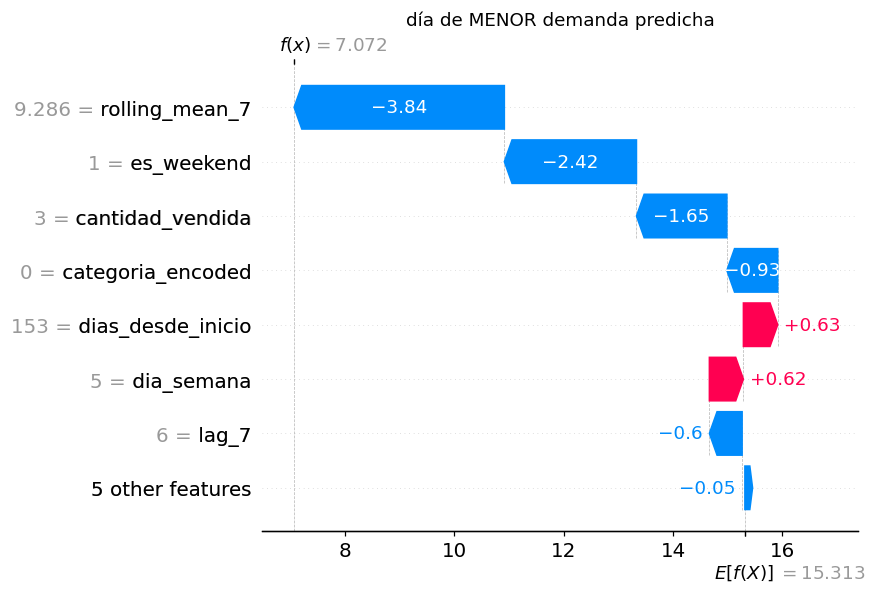

In [7]:
pred_e = svr.predict(Xe)
for titulo, idx in [("día de MAYOR demanda predicha", int(np.argmax(pred_e))),
                    ("día de MENOR demanda predicha", int(np.argmin(pred_e)))]:
    print(f"\n=== {titulo}: {pred_e[idx]:.1f} unidades ===")
    shap.plots.waterfall(sv[idx], max_display=8, show=False)
    plt.title(titulo); plt.tight_layout(); plt.show()

## 4.4. Integrated Gradients (relevancia por gradiente)

Los tres métodos anteriores no usan derivadas. **Integrated Gradients (IG)** es un
método de *relevancia por gradiente* — popular en redes neuronales — que aquí aplicamos
a la SVM porque su función con kernel RBF **es diferenciable**.

**Idea:** partimos de un día "neutro" (la media del entrenamiento, *baseline*) y nos
movemos en línea recta hasta el día a explicar. Vamos sumando el gradiente de la
predicción a lo largo de ese camino. La contribución de cada pista es:

$$IG_i(x) = (x_i - x'_i)\;\int_0^1 \frac{\partial f(x' + \alpha (x-x'))}{\partial x_i}\, d\alpha$$

Como `scikit-learn` no expone el gradiente, lo calculamos por **diferencias finitas**
(numérico) sobre `svr.predict`. IG cumple *completitud*: la suma de las contribuciones
debe igualar `f(x) - f(baseline)`; lo verificamos como prueba de que está bien hecho.

In [8]:
# --- Integrated Gradients por diferencias finitas sobre la SVR-RBF ---
def f(X):
    return svr.predict(np.atleast_2d(X))

baseline = X_train.mean(axis=0)          # un dia 'promedio' como punto de partida
h = 1e-2 * X_train.std(axis=0) + 1e-6    # paso de derivada, por feature

def integrated_gradients(x, baseline, steps=64):
    alphas = np.linspace(0, 1, steps)[:, None]
    path = baseline + alphas * (x - baseline)        # (steps, d)
    d = len(x); grads = np.zeros((steps, d))
    for j in range(d):
        hp = np.zeros(d); hp[j] = h[j]
        grads[:, j] = (f(path + hp) - f(path - hp)) / (2 * h[j])  # derivada central
    return (x - baseline) * grads.mean(axis=0)

# verificacion de COMPLETITUD en un caso
x0 = Xe[0]
ig0 = integrated_gradients(x0, baseline)
print(f'Suma de IG          : {ig0.sum():+.3f}')
print(f'f(x) - f(baseline)  : {f(x0)[0] - f(baseline)[0]:+.3f}')
print(f'Diferencia (debe ~0): {abs(ig0.sum() - (f(x0)[0]-f(baseline)[0])):.4f}')

Suma de IG          : -4.648
f(x) - f(baseline)  : -4.676
Diferencia (debe ~0): 0.0278


### 4.4.1. Relevancia global con IG y **comparación entre métodos**

Calculamos IG para una muestra de días y promediamos su magnitud `mean(|IG|)`.
Luego comparamos el *ranking* de IG con el de SHAP y el de permutación: si los tres
métodos —de familias distintas— coinciden en los factores de cabecera, la explicación
es **robusta** y no un artefacto de un método concreto.

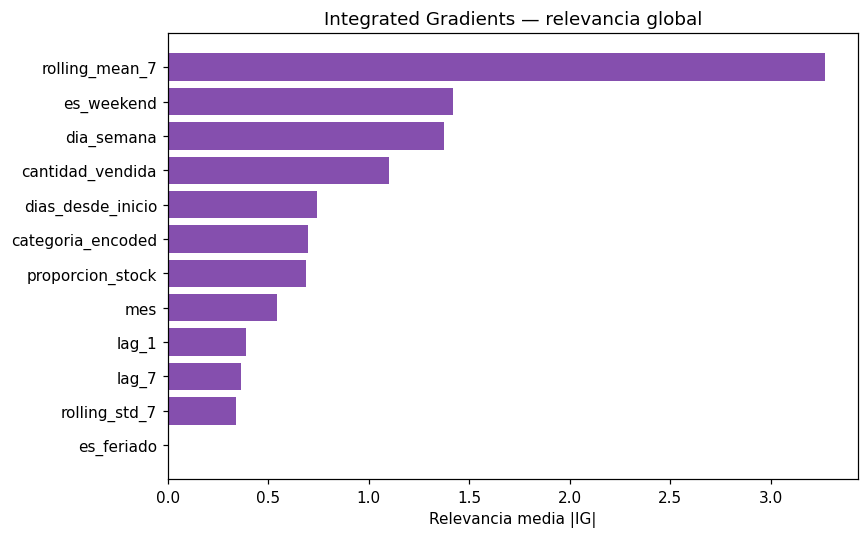

In [9]:
# IG global sobre la misma muestra Xe usada en SHAP
ig_all = np.vstack([integrated_gradients(x, baseline) for x in Xe])
ig_global = np.abs(ig_all).mean(axis=0)

order_ig = np.argsort(ig_global)
plt.figure(figsize=(8, 5))
plt.barh(np.array(FEATURES)[order_ig], ig_global[order_ig], color='#7030a0', alpha=0.85)
plt.xlabel('Relevancia media |IG|'); plt.title('Integrated Gradients — relevancia global')
plt.tight_layout(); plt.show()

In [10]:
# tabla comparativa de RANKINGS (1 = mas importante) entre los 3 metodos
import pandas as pd
shap_global = np.abs(sv.values).mean(axis=0)
perm_global = r.importances_mean

def ranking(vals):
    o = np.argsort(vals)[::-1]
    rk = np.empty(len(vals), int); rk[o] = np.arange(1, len(vals)+1)
    return rk

cmp = pd.DataFrame({
    'Feature': FEATURES,
    'Permutación': ranking(perm_global),
    'SHAP':        ranking(shap_global),
    'IntegratedGrad': ranking(ig_global),
}).sort_values('SHAP').reset_index(drop=True)
print(cmp.to_string(index=False))

top3 = lambda v: set(np.array(FEATURES)[np.argsort(v)[::-1][:3]])
comun = top3(perm_global) & top3(shap_global) & top3(ig_global)
print('\nFactores en el Top-3 de los TRES métodos:', comun or '(ninguno)')

          Feature  Permutación  SHAP  IntegratedGrad
   rolling_mean_7            1     1               1
       dia_semana            2     2               3
 proporcion_stock            4     3               7
 cantidad_vendida            5     4               4
       es_weekend            3     5               2
categoria_encoded            8     6               6
dias_desde_inicio            9     7               5
            lag_7           12     8              10
    rolling_std_7            7     9              11
              mes           10    10               8
            lag_1            6    11               9
       es_feriado           11    12              12

Factores en el Top-3 de los TRES métodos: {np.str_('dia_semana'), np.str_('rolling_mean_7')}


### 4.4.2. Explicación **local** con IG (un día concreto)

Para una predicción concreta, IG reparte la diferencia frente al día promedio entre las
pistas: en verde lo que **empuja la demanda hacia arriba**, en rojo lo que la baja.

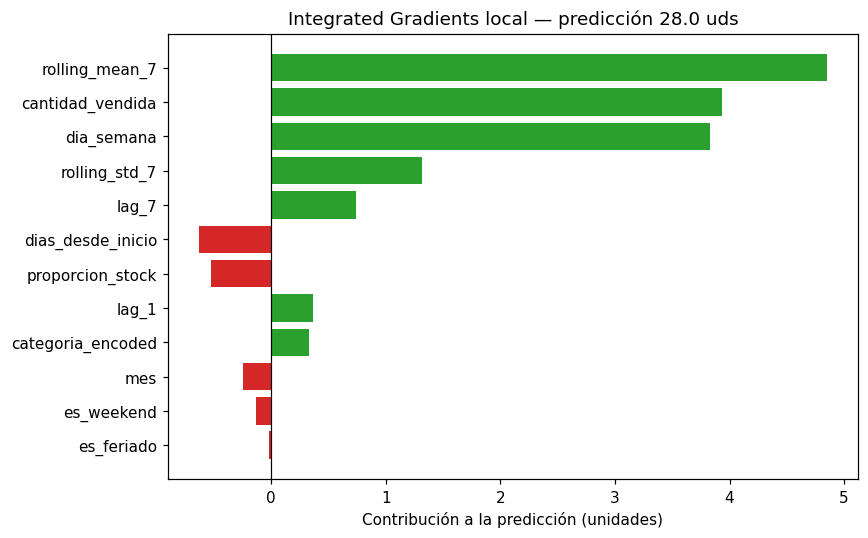

verde = sube la demanda  |  rojo = baja la demanda


In [11]:
idx = int(np.argmax(svr.predict(Xe)))     # el dia de mayor demanda predicha
ig_local = integrated_gradients(Xe[idx], baseline)
o = np.argsort(np.abs(ig_local))
colors = ['#2ca02c' if v > 0 else '#d62728' for v in ig_local[o]]
plt.figure(figsize=(8, 5))
plt.barh(np.array(FEATURES)[o], ig_local[o], color=colors)
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('Contribución a la predicción (unidades)')
plt.title(f'Integrated Gradients local — predicción {svr.predict(Xe[idx:idx+1])[0]:.1f} uds')
plt.tight_layout(); plt.show()
print('verde = sube la demanda  |  rojo = baja la demanda')

## 5. Conclusiones para el negocio

- **Factores que mandan en la demanda:** los indicadores temporales recientes
  (`lag_1`, `rolling_mean_7`, `cantidad_vendida`) dominan — la demanda de mañana se
  parece a la de los últimos días; el calendario y el stock matizan.
- **Acción:** la empresa puede anticipar reposiciones mirando estos pocos factores, y
  el modelo **justifica cada alerta** (waterfall) → confianza y trazabilidad.
- **Coherencia:** permutación, PDP y SHAP señalan los mismos factores, lo que valida
  la lectura.
- **Conclusión global del trabajo:** sobre el dataset de la Práctica 2, la **SVM/SVR
  iguala o supera** a modelos más complejos (LSTM/boosting) siendo **determinista,
  ligera y explicable** → la opción más práctica y atractiva para una empresa.